In [19]:
import tensorflow as tf
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [20]:
tf.random.set_seed(42)
np.random.seed(42)

In [21]:
df = pd.read_csv("./output_file.csv")

In [22]:
X = df[['w1', 'w2', 'w3', 'wPL']].values
y = df['range'].values

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [24]:
# Scale the features
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

In [25]:
# Scale the target variable
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1)).ravel()

In [26]:
pd.DataFrame(X_train_scaled).head()

,0,1,2,3
0,0.141916,-0.994273,0.302725,0.005905
1,-0.429056,0.578500,0.832225,-0.099824
2,1.462290,0.304974,-1.144577,1.450867
3,-0.821600,-0.925892,0.726325,0.534550
4,-1.392573,0.749453,-1.215177,1.133681


In [27]:
# Create the model
def create_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(512, activation='relu', input_shape=(4,)),
        tf.keras.layers.Dropout(0.1),
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dropout(0.1),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dropout(0.1),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dropout(0.1),
        tf.keras.layers.Dense(1)
    ])

    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                 loss='mse',
                 metrics=['mae'])
    return model

In [28]:
# Create and train the model
model = create_model()

/Users/danish/miniforge3/lib/python3.10/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [29]:
# Early stopping callback
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=50,
    restore_best_weights=True
)

In [30]:
# Train the model
history = model.fit(
    X_train_scaled,
    y_train_scaled,
    epochs=1000,
    batch_size=8,
    validation_split=0.2,
    # callbacks=[early_stopping],
    verbose=1
)


Epoch 1/1000
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.0374 - mae: 0.7854 - val_loss: 1.0228 - val_mae: 0.7782
Epoch 2/1000
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0252 - mae: 0.7693 - val_loss: 0.9976 - val_mae: 0.7789
Epoch 3/1000
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0164 - mae: 0.7643 - val_loss: 1.0020 - val_mae: 0.7808
Epoch 4/1000
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0120 - mae: 0.7675 - val_loss: 0.9972 - val_mae: 0.7741
Epoch 5/1000
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0174 - mae: 0.7641 - val_loss: 0.9921 - val_mae: 0.7812
Epoch 6/1000
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9862 - mae: 0.7518 - val_loss: 0.9992 - val_mae: 0.7780
Epoch 7/1000
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0031 - mae: 0.7625 - val_loss: 1.0345 - val_mae: 0.7851
Epoch 8/1000
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0226 - mae: 0.7678 - val_loss: 1.0172 - val_mae: 0.7845
Epoch 9/1000
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - lo

In [31]:
# Function to make predictions
def predict_range(w1, w2, w3, wPL):
    # Prepare input data
    input_data = np.array([[w1, w2, w3, wPL]])
    
    # Scale input data
    input_scaled = scaler_X.transform(input_data)
    
    # Make prediction
    prediction_scaled = model.predict(input_scaled)
    
    # Inverse transform the prediction
    prediction = scaler_y.inverse_transform(prediction_scaled.reshape(-1, 1))
    
    return prediction[0][0]


In [32]:
# Evaluate the model
train_predictions = scaler_y.inverse_transform(model.predict(X_train_scaled).reshape(-1, 1))
test_predictions = scaler_y.inverse_transform(model.predict(X_test_scaled).reshape(-1, 1))

train_mse = np.mean((train_predictions.ravel() - y_train) ** 2)
test_mse = np.mean((test_predictions.ravel() - y_test) ** 2)
train_rmse = np.sqrt(train_mse)
test_rmse = np.sqrt(test_mse)

print(f"Training RMSE: {train_rmse:.2f}")
print(f"Testing RMSE: {test_rmse:.2f}")


18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 565us/step
Training RMSE: 15.00
Testing RMSE: 29.57


In [33]:
# Example prediction
example_input = X[0]  # First row of the dataset
predicted_range = predict_range(example_input[0], example_input[1], example_input[2], example_input[3])
print(f"\nExample prediction:")
print(f"Input (w1, w2, w3): {example_input}")
print(f"Predicted range: {predicted_range:.2f}")
print(f"Actual range: {y[0]:.2f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

Example prediction:
Input (w1, w2, w3): [1.9e-01 6.3e-01 9.4e-01 2.9e-05]
Predicted range: 168.15
Actual range: 168.58


In [34]:

import matplotlib.pyplot as plt


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 765us/step


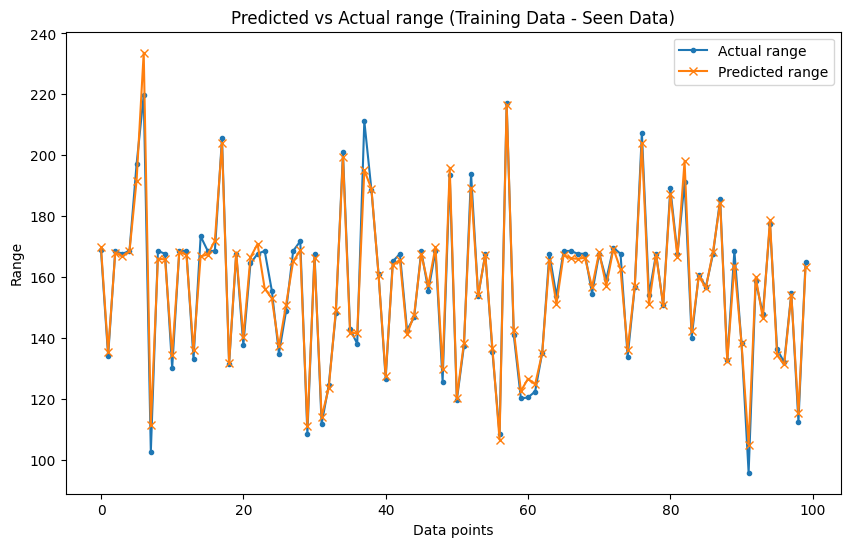

In [35]:
# Predict the range for 100 data points from training set and plot the predictions against the actual values

# Prepare the data

X_train_sample = X_train_scaled[:100]
y_train_sample = y_train[:100]

# Make predictions

train_predictions_sample = scaler_y.inverse_transform(model.predict(X_train_sample).reshape(-1, 1))

# Plot the predictions

plt.figure(figsize=(10, 6))
plt.plot(y_train_sample, label='Actual range', marker='.')
plt.plot(train_predictions_sample, label='Predicted range', marker='x')
plt.xlabel('Data points')
plt.ylabel('Range')
plt.title('Predicted vs Actual range (Training Data - Seen Data)')
plt.legend()
plt.show()


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 661us/step


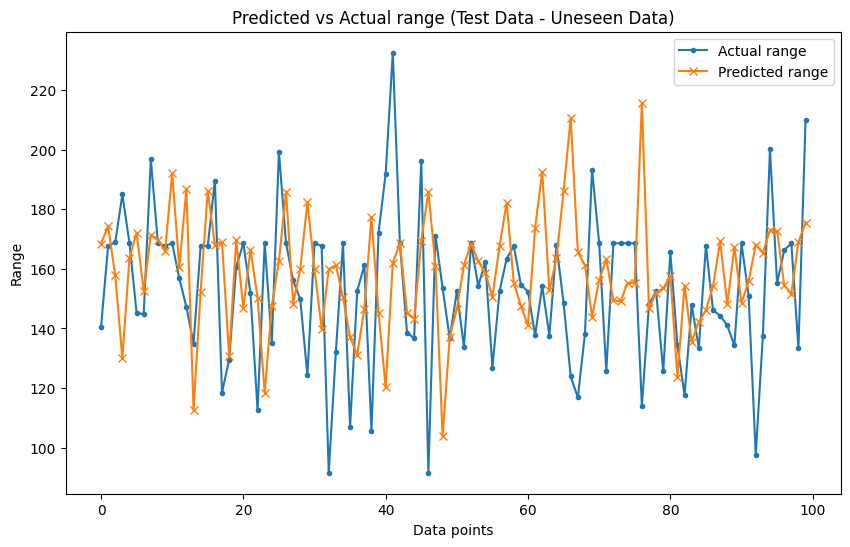

In [36]:
# Predict the range for 100 data points from testing set and plot the predictions against the actual values

# Prepare the data

X_test_sample = X_test_scaled[:100]
y_test_sample = y_test[:100]

# Make predictions

test_predictions_sample = scaler_y.inverse_transform(model.predict(X_test_sample).reshape(-1, 1))

# Plot the predictions

plt.figure(figsize=(10, 6))
plt.plot(y_test_sample, label='Actual range', marker='.')
plt.plot(test_predictions_sample, label='Predicted range', marker='x')
plt.xlabel('Data points')
plt.ylabel('Range')
plt.title('Predicted vs Actual range (Test Data - Uneseen Data)')

plt.legend()
plt.show()



In [37]:
# Saving the model to disk

model.save('DNN_Range_Predictions.h5')